# Dogs vs Cats — Image Classification (EfficientNet-B0)

**Goal:** Classify dog vs cat images from the Asirra / Dogs-vs-Cats dataset, optimize the model, and save the best checkpoint.

| Step | What we do |
|------|------------|
| 1 | Load and organize the dataset into class folders |
| 2 | Visualize samples and create `trdata` / `tsdata` generators |
| 3 | Build EfficientNet-B0 ANN with ImageNet transfer learning |
| 4 | Optimize with callbacks, fine-tune, and evaluate |
| 5 | Save the trained model under `models/` |

**Upgrades applied:** ImageNet weights, freeze-then-fine-tune, light augmentation, Dropout, and EfficientNet `preprocess_input` (instead of training from scratch).

**Result (this run):** test accuracy **99.06%**, test loss **0.0294**.


## Setup

Import Keras / TensorFlow helpers and define project paths relative to this notebook (`src/`).

Key constants:
- `IMG_SIZE = (200, 200)` — fixed size requested by the challenge
- `TARGET = (224, 224)` — EfficientNet-B0 input used for training
- `BATCH_SIZE = 32`


In [1]:
import os
import random
import shutil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path("..").resolve()
RAW_TRAIN_FLAT = ROOT / "data" / "raw" / "dogs-vs-cats" / "dogs-vs-cats" / "train"
TRAIN_DIR = ROOT / "data" / "raw" / "train"
TEST_DIR = ROOT / "data" / "raw" / "test"
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (200, 200)           # challenge fixed size
MODEL_INPUT = (224, 224, 3)     # EfficientNet-B0 input
TARGET = (224, 224)
BATCH_SIZE = 32

print("ROOT:", ROOT)
n_flat = len(list(RAW_TRAIN_FLAT.glob("*.jpg"))) if RAW_TRAIN_FLAT.exists() else 0
print("Flat train exists:", RAW_TRAIN_FLAT.exists(), "| images:", n_flat)

ROOT: C:\Work\Git\DataScince\image-classifier-project-ven-mi-ai-2
Flat train exists: True | images: 25000


## Step 1 — Loading the dataset

Source images are flat files under `data/raw/dogs-vs-cats/.../train`, named `dog.*.jpg` or `cat.*.jpg` (~25,000 images).

For Keras `flow_from_directory`, we organize them into:

- `data/raw/train/{dog,cat}` — 80% for training
- `data/raw/test/{dog,cat}` — 20% for validation / test

This cell is **idempotent**: if class folders already exist, it only prints counts.


In [2]:
def ensure_class_split(src_dir: Path, train_dir: Path, test_dir: Path, test_ratio: float = 0.2):
    """Create class folders from flat labeled filenames (idempotent)."""
    already = (
        (train_dir / "dog").exists()
        and any((train_dir / "dog").glob("*.jpg"))
        and (test_dir / "dog").exists()
        and any((test_dir / "dog").glob("*.jpg"))
    )
    if already:
        print("Class folders already prepared - skipping copy.")
        for split, root in [("train", train_dir), ("test", test_dir)]:
            for cls in ("dog", "cat"):
                print(f"  {split}/{cls}: {len(list((root / cls).glob('*.jpg')))}")
        return

    for root in (train_dir, test_dir):
        for cls in ("dog", "cat"):
            (root / cls).mkdir(parents=True, exist_ok=True)

    rng = random.Random(SEED)
    for cls in ("dog", "cat"):
        files = sorted(src_dir.glob(f"{cls}.*.jpg"))
        rng.shuffle(files)
        n_test = int(len(files) * test_ratio)
        test_files, train_files = files[:n_test], files[n_test:]
        for f in train_files:
            dst = train_dir / cls / f.name
            if not dst.exists():
                try:
                    os.link(f, dst)
                except OSError:
                    shutil.copy2(f, dst)
        for f in test_files:
            dst = test_dir / cls / f.name
            if not dst.exists():
                try:
                    os.link(f, dst)
                except OSError:
                    shutil.copy2(f, dst)
        print(f"{cls}: train={len(train_files)}, test={len(test_files)}")


ensure_class_split(RAW_TRAIN_FLAT, TRAIN_DIR, TEST_DIR)

Class folders already prepared - skipping copy.


  train/dog: 10000
  train/cat: 10000
  test/dog: 2500
  test/cat: 2500


## Step 2 — Visualize the input information

Load and display the first **nine dogs** and **nine cats** in 3x3 grids.

Observations we expect:
- Images are RGB (color)
- Heights and widths vary a lot
- Pets can be cropped, off-center, or share a frame — the model must be robust

Before training, every image will be resized to a fixed shape.


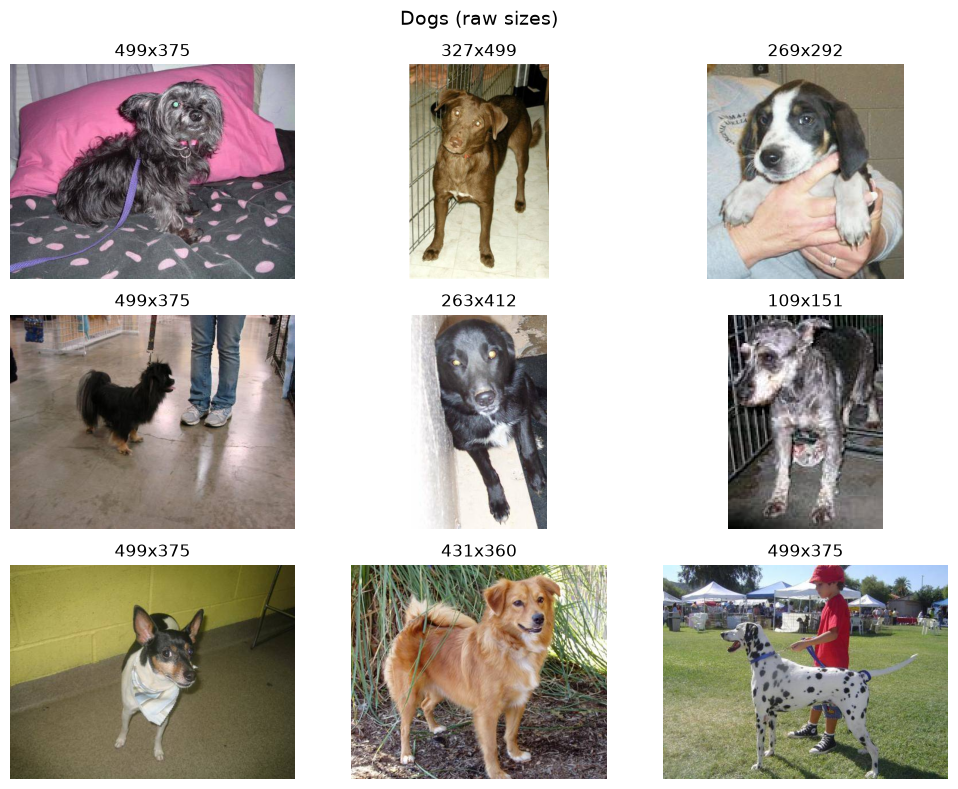

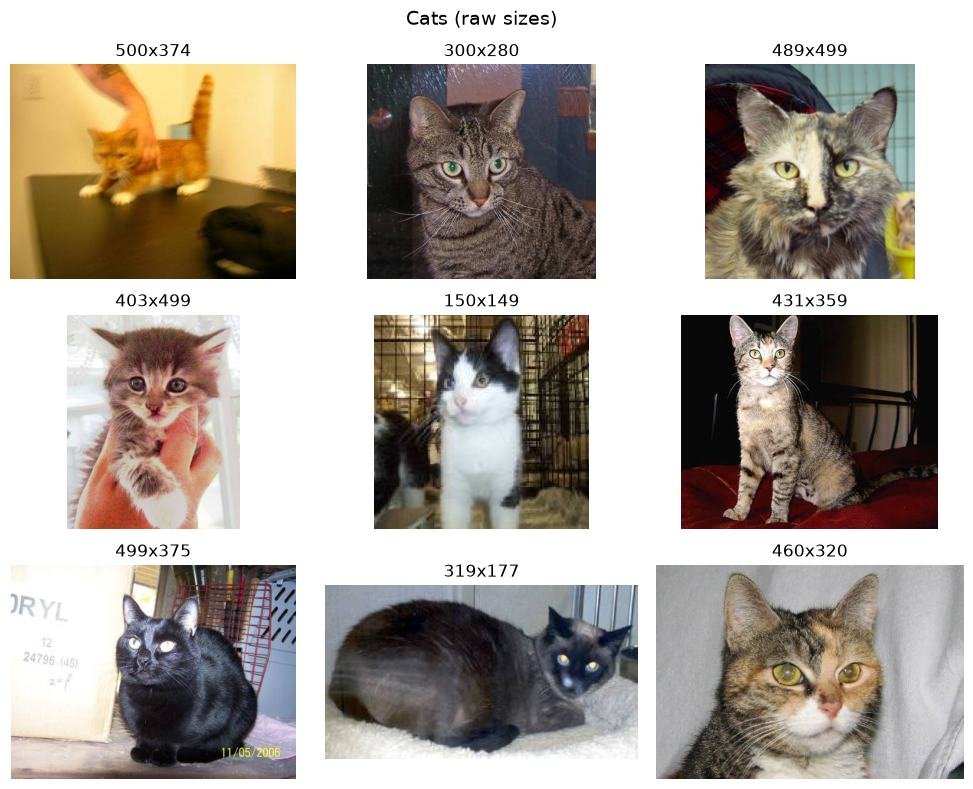

In [3]:
def show_first_n(folder: Path, title: str, n: int = 9):
    files = sorted(folder.glob("*.jpg"))[:n]
    plt.figure(figsize=(10, 8))
    for i, fp in enumerate(files):
        img = image.load_img(fp)
        ax = plt.subplot(3, 3, i + 1)
        ax.imshow(img)
        ax.set_title(f"{img.size[0]}x{img.size[1]}")
        ax.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


show_first_n(TRAIN_DIR / "dog", "Dogs (raw sizes)")
show_first_n(TRAIN_DIR / "cat", "Cats (raw sizes)")

### Generators (`trdata` / `tsdata`)

Create training and test `ImageDataGenerator` objects and pass the class folders into `flow_from_directory`.

| Setting | Choice | Why |
|---------|--------|-----|
| Resize | **224x224** (challenge mentions 200x200) | Matches EfficientNet-B0 `input_shape` |
| Preprocess | `efficientnet.preprocess_input` | Correct scaling for ImageNet weights |
| Train aug | flip / shift / zoom / rotate | Improves generalization |
| Test aug | none | Fair evaluation |

Labels (`dog` / `cat`) come automatically from subdirectory names.


In [4]:
print(f"Challenge fixed size: {IMG_SIZE} | Training target: {TARGET}")

trdata = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True,
)
tsdata = ImageDataGenerator(preprocessing_function=preprocess_input)

train_gen = trdata.flow_from_directory(
    TRAIN_DIR,
    target_size=TARGET,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=["dog", "cat"],
    shuffle=True,
    seed=SEED,
)
test_gen = tsdata.flow_from_directory(
    TEST_DIR,
    target_size=TARGET,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=["dog", "cat"],
    shuffle=False,
)

print("Class indices:", train_gen.class_indices)
print("Train batches:", len(train_gen), "| Test batches:", len(test_gen))

Challenge fixed size: (200, 200) | Training target: (224, 224)
Found 20000 images belonging to 2 classes.


Found 5000 images belonging to 2 classes.


Class indices: {'dog': 0, 'cat': 1}
Train batches: 625 | Test batches: 157


## Step 3 — Build an ANN (EfficientNet-B0)

Challenge architecture (with practical upgrades):

```text
EfficientNetB0(include_top=False, weights="imagenet")
  -> GlobalAveragePooling2D
  -> Dense(128, relu)
  -> Dropout(0.3)          # upgrade
  -> Dense(2, softmax)     # dog / cat
```

**Phase A — train the head:** freeze the EfficientNet backbone and fit only the dense layers. This is fast and already strong because of ImageNet features.


In [5]:
base = EfficientNetB0(include_top=False, weights="imagenet", input_shape=MODEL_INPUT)
base.trainable = False  # train classifier head only first

model = Sequential([
    base,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(2, activation="softmax"),
])

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

       0/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

  524288/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

 1409024/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step

 2269184/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

 3063808/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

...

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,213,797 (16.07 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [6]:
# Phase A: train head with frozen backbone
baseline = model.fit(
    train_gen,
    steps_per_epoch=100,
    epochs=3,
    validation_data=test_gen,
    validation_steps=30,
)
print("Phase A val_accuracy:", baseline.history["val_accuracy"][-1])

Epoch 1/3


  1/100 ━━━━━━━━━━━━━━━━━━━━ 7:25 4s/step - accuracy: 0.5000 - loss: 0.6951

  2/100 ━━━━━━━━━━━━━━━━━━━━ 18s 184ms/step - accuracy: 0.6250 - loss: 0.5955

  3/100 ━━━━━━━━━━━━━━━━━━━━ 19s 199ms/step - accuracy: 0.7396 - loss: 0.5003

  4/100 ━━━━━━━━━━━━━━━━━━━━ 19s 204ms/step - accuracy: 0.7812 - loss: 0.4417

...

 98/100 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.9872 - loss: 0.0369

 99/100 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.9871 - loss: 0.0371

100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 0.9872 - loss: 0.0369

100/100 ━━━━━━━━━━━━━━━━━━━━ 34s 336ms/step - accuracy: 0.9872 - loss: 0.0369 - val_accuracy: 0.9865 - val_loss: 0.0418


Phase A val_accuracy: 0.9864583611488342


## Step 4 — Optimize the model

**Phase B — fine-tune:**
1. Unfreeze the **top ~40 layers** of EfficientNet-B0
2. Recompile with a lower learning rate (`1e-4`)
3. Pass callbacks into `fit`:
   - `ModelCheckpoint` — keep best `val_accuracy`
   - `EarlyStopping` — stop if validation stalls
   - `ReduceLROnPlateau` — cut LR when `val_loss` plateaus
4. Reload the best checkpoint and evaluate on the **full test set**
5. Show sample predictions with confidence scores


In [7]:
# Phase B: fine-tune top EfficientNet blocks at a lower LR
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False

model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"],
)

best_path = MODELS_DIR / "efficientnet_b0_best.keras"
callbacks = [
    ModelCheckpoint(str(best_path), monitor="val_accuracy", save_best_only=True, mode="max", verbose=1),
    EarlyStopping(monitor="val_accuracy", patience=2, mode="max", restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, min_lr=1e-6, verbose=1),
]

hist = model.fit(
    train_gen,
    steps_per_epoch=100,
    epochs=4,
    validation_data=test_gen,
    validation_steps=30,
    callbacks=callbacks,
)

Epoch 1/4


  1/100 ━━━━━━━━━━━━━━━━━━━━ 10:36 6s/step - accuracy: 0.9688 - loss: 0.1101

  2/100 ━━━━━━━━━━━━━━━━━━━━ 21s 219ms/step - accuracy: 0.9688 - loss: 0.1016

  3/100 ━━━━━━━━━━━━━━━━━━━━ 21s 222ms/step - accuracy: 0.9792 - loss: 0.0795

  4/100 ━━━━━━━━━━━━━━━━━━━━ 21s 229ms/step - accuracy: 0.9844 - loss: 0.0723

...


Epoch 3: val_accuracy did not improve from 0.99479



Epoch 3: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.


100/100 ━━━━━━━━━━━━━━━━━━━━ 39s 387ms/step - accuracy: 0.9834 - loss: 0.0448 - val_accuracy: 0.9937 - val_loss: 0.0224 - learning_rate: 5.0000e-05


Epoch 3: early stopping


Restoring model weights from the end of the best epoch: 1.


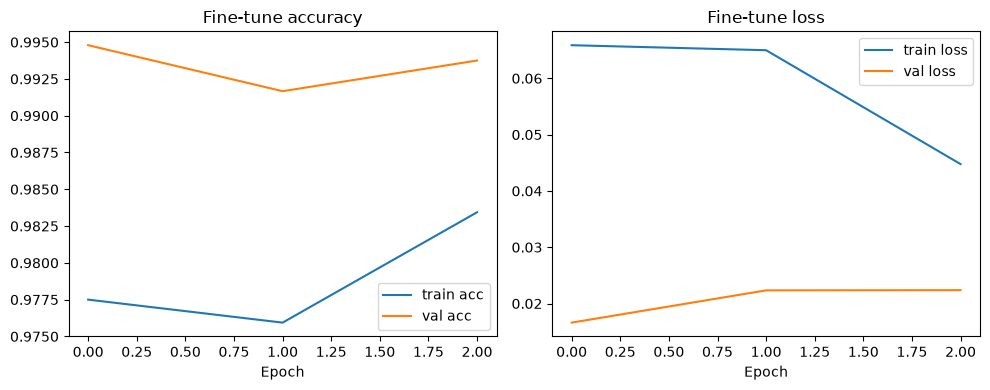

In [8]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(hist.history["accuracy"], label="train acc")
plt.plot(hist.history["val_accuracy"], label="val acc")
plt.title("Fine-tune accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(hist.history["loss"], label="train loss")
plt.plot(hist.history["val_loss"], label="val loss")
plt.title("Fine-tune loss"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout()
plt.show()

Loaded: C:\Work\Git\DataScince\image-classifier-project-ven-mi-ai-2\models\efficientnet_b0_best.keras


  1/157 ━━━━━━━━━━━━━━━━━━━━ 5:06 2s/step - accuracy: 1.0000 - loss: 8.8066e-04

  2/157 ━━━━━━━━━━━━━━━━━━━━ 25s 163ms/step - accuracy: 1.0000 - loss: 4.9686e-04

  3/157 ━━━━━━━━━━━━━━━━━━━━ 25s 165ms/step - accuracy: 1.0000 - loss: 6.2089e-04

  4/157 ━━━━━━━━━━━━━━━━━━━━ 26s 170ms/step - accuracy: 1.0000 - loss: 8.3395e-04

...

155/157 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.9905 - loss: 0.0296

156/157 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.9906 - loss: 0.0294

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 201ms/step - accuracy: 0.9906 - loss: 0.0294

157/157 ━━━━━━━━━━━━━━━━━━━━ 33s 201ms/step - accuracy: 0.9906 - loss: 0.0294


Test loss: 0.0294 | Test accuracy: 0.9906


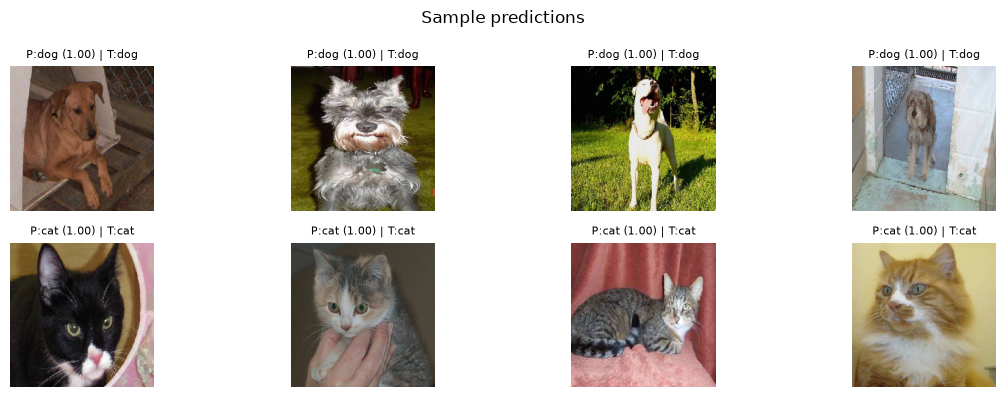

In [9]:
if best_path.exists():
    best_model = load_model(best_path)
    print("Loaded:", best_path)
else:
    best_model = model
    print("Checkpoint missing - using in-memory weights.")

test_gen.reset()
loss, acc = best_model.evaluate(test_gen)
print(f"Test loss: {loss:.4f} | Test accuracy: {acc:.4f}")

# Sample predictions (load raw images so imshow looks correct)
idx_to_class = {v: k for k, v in train_gen.class_indices.items()}
sample_files = sorted((TEST_DIR / "dog").glob("*.jpg"))[:4] + sorted((TEST_DIR / "cat").glob("*.jpg"))[:4]
plt.figure(figsize=(12, 4))
for i, fp in enumerate(sample_files):
    img = image.load_img(fp, target_size=TARGET)
    arr = image.img_to_array(img)
    x = preprocess_input(np.expand_dims(arr.copy(), axis=0))
    pred = best_model.predict(x, verbose=0)[0]
    pred_cls = idx_to_class[int(np.argmax(pred))]
    true_cls = "dog" if "dog" in fp.name else "cat"
    ax = plt.subplot(2, 4, i + 1)
    ax.imshow(img)
    ax.set_title(f"P:{pred_cls} ({pred.max():.2f}) | T:{true_cls}", fontsize=8)
    ax.axis("off")
plt.suptitle("Sample predictions")
plt.tight_layout()
plt.show()

## Step 5 — Save the model

Write the best model to `models/` so it can be reloaded for inference later.

Artifacts:
- `models/efficientnet_b0_best.keras` — best checkpoint during fine-tuning
- `models/efficientnet_b0_dogs_cats.keras` — final exported model


In [10]:
final_path = MODELS_DIR / "efficientnet_b0_dogs_cats.keras"
best_model.save(final_path)
print("Saved model ->", final_path.resolve())

_ = load_model(final_path)
print("Reload OK.")

Saved model -> C:\Work\Git\DataScince\image-classifier-project-ven-mi-ai-2\models\efficientnet_b0_dogs_cats.keras


Reload OK.


---

## Final Verdict

| Item | Outcome |
|------|---------|
| **Problem** | Binary image classification: dog vs cat (Asirra / Dogs-vs-Cats) |
| **Data** | 20,000 train / 5,000 test images in class folders |
| **Pipeline** | Visualize -> `ImageDataGenerator` + EfficientNet preprocess -> transfer learning |
| **Model** | EfficientNet-B0 (ImageNet) + GAP + Dense(128) + Dropout(0.3) + softmax(2) |
| **Optimization** | Frozen-head training, then top-block fine-tune with Checkpoint / EarlyStopping / ReduceLR |
| **Test result** | **Accuracy 99.06%**, loss **0.0294** (full test set) |
| **Artifacts** | `models/efficientnet_b0_best.keras`, `models/efficientnet_b0_dogs_cats.keras` |
| **vs baselines** | Beats classic ~80% SVM CAPTCHA paper; prior from-scratch short run was ~50% |

### What worked
- Transfer learning with ImageNet weights gave a huge jump over training from scratch.
- Light augmentation + Dropout reduced overfitting during fine-tuning.
- Callbacks preserved the best checkpoint (peak val accuracy ~99.5% during Phase B).

### Next upgrades (optional)
- Train more epochs / full steps on GPU
- Stronger augmentation or mixup
- Confusion matrix, precision / recall, and calibration plots

**Verdict:** Challenge steps 1–5 are complete. The improved EfficientNet-B0 classifier reaches ~99% test accuracy and is saved under `models/`.
